In [1]:
import pandas as pd

df = pd.read_csv("chennai_era5.csv")

print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (52608, 9)

Column names:
['valid_time', 'u10', 'v10', 'd2m', 't2m', 'msl', 'sp', 'latitude', 'longitude']

First 5 rows:


,valid_time,u10,v10,d2m,t2m,msl,sp,latitude,longitude
0,2020-01-01 00:00:00,-1.243286,-1.010696,296.21140,297.75104,101305.560,101182.42,13.0,80.25
1,2020-01-01 01:00:00,-0.978210,-1.176605,295.90924,297.56055,101380.560,101257.58,13.0,80.25
2,2020-01-01 02:00:00,-1.140427,-1.171417,296.29797,297.76080,101464.250,101341.05,13.0,80.25
3,2020-01-01 03:00:00,-1.562012,-1.361420,296.51865,297.96436,101590.125,101467.59,13.0,80.25
4,2020-01-01 04:00:00,-2.180756,-1.489899,296.69305,298.36432,101638.250,101514.62,13.0,80.25



Data types:
valid_time     object
u10           float64
v10           float64
d2m           float64
t2m           float64
msl           float64
sp            float64
latitude      float64
longitude     float64
dtype: object

Missing values:
valid_time    0
u10           0
v10           0
d2m           0
t2m           0
msl           0
sp            0
latitude      0
longitude     0
dtype: int64

Duplicate rows: 0


In [2]:
# STEP 1: RAW DATA AUDIT

import pandas as pd
import numpy as np

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nMissing values per column:")
print(df.isna().sum())

print("\nDuplicate full rows:", df.duplicated().sum())

print("\nMemory usage:")
print(f"{df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Dataset shape: (52608, 9)

Column names:
['valid_time', 'u10', 'v10', 'd2m', 't2m', 'msl', 'sp', 'latitude', 'longitude']

Data types:
valid_time     object
u10           float64
v10           float64
d2m           float64
t2m           float64
msl           float64
sp            float64
latitude      float64
longitude     float64
dtype: object

First 5 rows:


,valid_time,u10,v10,d2m,t2m,msl,sp,latitude,longitude
0,2020-01-01 00:00:00,-1.243286,-1.010696,296.21140,297.75104,101305.560,101182.42,13.0,80.25
1,2020-01-01 01:00:00,-0.978210,-1.176605,295.90924,297.56055,101380.560,101257.58,13.0,80.25
2,2020-01-01 02:00:00,-1.140427,-1.171417,296.29797,297.76080,101464.250,101341.05,13.0,80.25
3,2020-01-01 03:00:00,-1.562012,-1.361420,296.51865,297.96436,101590.125,101467.59,13.0,80.25
4,2020-01-01 04:00:00,-2.180756,-1.489899,296.69305,298.36432,101638.250,101514.62,13.0,80.25



Last 5 rows:


,valid_time,u10,v10,d2m,t2m,msl,sp,latitude,longitude
52603,2025-12-31 19:00:00,-0.741577,-2.154160,296.38700,298.30316,101064.000,100942.050,13.0,80.25
52604,2025-12-31 20:00:00,-0.739471,-1.945709,296.24010,298.12220,100996.690,100874.516,13.0,80.25
52605,2025-12-31 21:00:00,-0.824554,-1.919098,296.15607,298.13107,100960.375,100838.290,13.0,80.25
52606,2025-12-31 22:00:00,0.066818,-2.003342,296.00415,297.60217,100943.250,100820.750,13.0,80.25
52607,2025-12-31 23:00:00,0.233627,-2.351181,296.04562,297.60178,100991.750,100869.055,13.0,80.25



Missing values per column:
valid_time    0
u10           0
v10           0
d2m           0
t2m           0
msl           0
sp            0
latitude      0
longitude     0
dtype: int64

Duplicate full rows: 0

Memory usage:
6.62 MB


In [3]:
 #STEP 2: DATETIME VALIDATION

df["valid_time"] = pd.to_datetime(
    df["valid_time"],
    errors="coerce"
)

print("Datetime data type:")
print(df["valid_time"].dtype)

print("\nInvalid timestamps:")
print(df["valid_time"].isna().sum())

print("\nStart time:", df["valid_time"].min())
print("End time:", df["valid_time"].max())

print("\nAlready chronological:",
      df["valid_time"].is_monotonic_increasing)

print("\nDuplicate timestamps:",
      df["valid_time"].duplicated().sum())

Datetime data type:
datetime64[ns]

Invalid timestamps:
0

Start time: 2020-01-01 00:00:00
End time: 2025-12-31 23:00:00

Already chronological: True

Duplicate timestamps: 0


In [4]:
# STEP 3: HOURLY CONTINUITY CHECK

# 1. Time difference between consecutive rows
time_diff = df["valid_time"].diff()

print("Time interval counts:")
print(time_diff.value_counts().head())

# 2. Check intervals other than 1 hour
unusual_intervals = time_diff[
    time_diff.notna() &
    (time_diff != pd.Timedelta(hours=1))
]

print("\nUnusual intervals:", len(unusual_intervals))

# 3. Check how many hourly timestamps are expected
expected_hours = int(
    (df["valid_time"].max() - df["valid_time"].min())
    / pd.Timedelta(hours=1)
) + 1

print("Expected hourly rows:", expected_hours)
print("Actual rows:", len(df))

# 4. Check missing timestamps
expected_time = pd.date_range(
    start=df["valid_time"].min(),
    end=df["valid_time"].max(),
    freq="h"
)

missing_times = expected_time.difference(df["valid_time"])

print("Missing timestamps:", len(missing_times))
print("\nFirst missing timestamps, if any:")
print(missing_times[:10])

Time interval counts:
valid_time
0 days 01:00:00    52607
Name: count, dtype: int64

Unusual intervals: 0
Expected hourly rows: 52608
Actual rows: 52608
Missing timestamps: 0

First missing timestamps, if any:
DatetimeIndex([], dtype='datetime64[ns]', freq='h')


In [5]:
# STEP 4A: PRESERVE RAW DATA

weather = df.copy()

# STEP 4B: VERIFY RAW VALUE RANGES
print("Raw value ranges:")
display(weather[["t2m", "d2m", "msl", "sp", "u10", "v10"]].agg(["min", "max"]))

# STEP 4C: CONVERT UNITS
weather["t2m_C"] = weather["t2m"] - 273.15
weather["d2m_C"] = weather["d2m"] - 273.15

weather["msl_hPa"] = weather["msl"] / 100
weather["sp_hPa"] = weather["sp"] / 100

# STEP 4D: CHECK WIND COMPONENTS (keep original m/s values)
print("\nWind component ranges (original units):")
display(weather[["u10", "v10"]].agg(["min", "max"]))

# STEP 4E: VERIFY CONVERSIONS
print("\nConverted values:")
display(
    weather[
        ["valid_time", "t2m_C", "d2m_C", "msl_hPa", "sp_hPa", "u10", "v10"]
    ].head()
)

Raw value ranges:


,t2m,d2m,msl,sp,u10,v10
min,293.90448,289.26830,99538.875,99418.46,-12.994949,-14.342789
max,310.89900,302.45584,101980.000,101855.89,12.196396,14.635376



Wind component ranges (original units):


,u10,v10
min,-12.994949,-14.342789
max,12.196396,14.635376



Converted values:


,valid_time,t2m_C,d2m_C,msl_hPa,sp_hPa,u10,v10
0,2020-01-01 00:00:00,24.60104,23.06140,1013.05560,1011.8242,-1.243286,-1.010696
1,2020-01-01 01:00:00,24.41055,22.75924,1013.80560,1012.5758,-0.978210,-1.176605
2,2020-01-01 02:00:00,24.61080,23.14797,1014.64250,1013.4105,-1.140427,-1.171417
3,2020-01-01 03:00:00,24.81436,23.36865,1015.90125,1014.6759,-1.562012,-1.361420
4,2020-01-01 04:00:00,25.21432,23.54305,1016.38250,1015.1462,-2.180756,-1.489899


In [6]:
import numpy as np
weather["wind_speed_ms"] = np.sqrt(weather["u10"]**2 + weather["v10"]**2)
weather["wind_speed_kmh"] = weather["wind_speed_ms"]*3.6
display(
    weather[["valid_time","u10","v10","wind_speed_ms","wind_speed_kmh"]].head())
print("\nwind speed summary:")
display(weather[["wind_speed_ms","wind_speed_kmh"]].describe())

,valid_time,u10,v10,wind_speed_ms,wind_speed_kmh
0,2020-01-01 00:00:00,-1.243286,-1.010696,1.602269,5.768170
1,2020-01-01 01:00:00,-0.978210,-1.176605,1.530129,5.508465
2,2020-01-01 02:00:00,-1.140427,-1.171417,1.634867,5.885522
3,2020-01-01 03:00:00,-1.562012,-1.361420,2.072039,7.459339
4,2020-01-01 04:00:00,-2.180756,-1.489899,2.641116,9.508017



wind speed summary:


,wind_speed_ms,wind_speed_kmh
count,52608.000000,52608.000000
mean,3.582839,12.898219
std,1.441150,5.188139
min,0.017356,0.062483
25%,2.593814,9.337732
50%,3.562318,12.824345
75%,4.515485,16.255746
max,15.087575,54.315271


In [7]:
weather["hour"] = weather["valid_time"].dt.hour
weather["day"] = weather["valid_time"].dt.day
weather["month"] = weather["valid_time"].dt.month
weather["year"] = weather["valid_time"].dt.year
weather["day_of_week"] = weather["valid_time"].dt.dayofweek
display(
    weather[
        ["valid_time","hour","day","month","year","day_of_week"]
        ].head())

,valid_time,hour,day,month,year,day_of_week
0,2020-01-01 00:00:00,0,1,1,2020,2
1,2020-01-01 01:00:00,1,1,1,2020,2
2,2020-01-01 02:00:00,2,1,1,2020,2
3,2020-01-01 03:00:00,3,1,1,2020,2
4,2020-01-01 04:00:00,4,1,1,2020,2


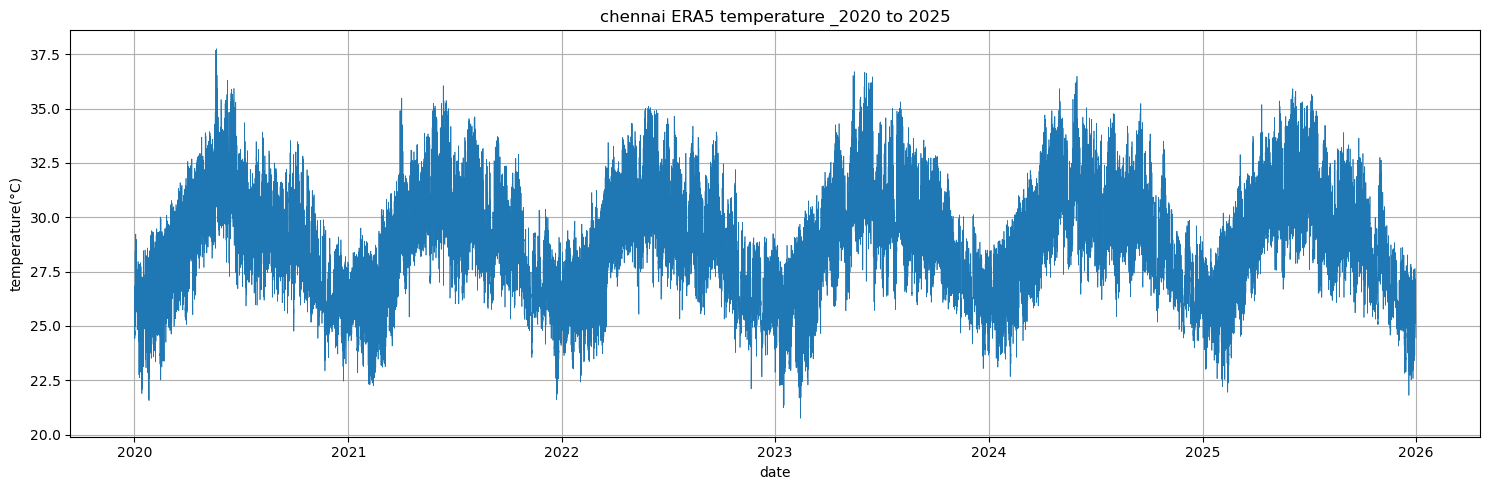

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
plt.plot(weather["valid_time"],weather["t2m_C"],linewidth=0.5)
plt.title("chennai ERA5 temperature _2020 to 2025")
plt.xlabel("date")
plt.ylabel("temperature(\u00b0C)")
plt.grid(True)
plt.tight_layout()
plt.show()

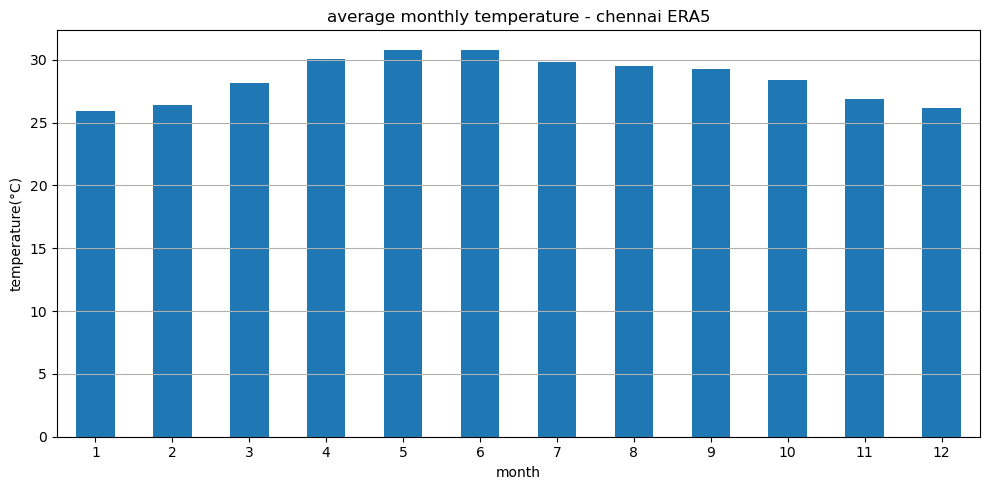

month
1     25.896232
2     26.373352
3     28.154415
4     30.057528
5     30.764167
6     30.799132
7     29.809708
8     29.462824
9     29.277971
10    28.382842
11    26.845041
12    26.131461
Name: t2m_C, dtype: float64

In [9]:
monthly_temp = weather.groupby("month")["t2m_C"].mean()
plt.figure(figsize=(10,5))
monthly_temp.plot(kind="bar")
plt.title("average monthly temperature - chennai ERA5")
plt.xlabel("month")
plt.ylabel("temperature(\u00b0C)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()
display(monthly_temp)

In [10]:
print(weather.columns.tolist())

['valid_time', 'u10', 'v10', 'd2m', 't2m', 'msl', 'sp', 'latitude', 'longitude', 't2m_C', 'd2m_C', 'msl_hPa', 'sp_hPa', 'wind_speed_ms', 'wind_speed_kmh', 'hour', 'day', 'month', 'year', 'day_of_week']


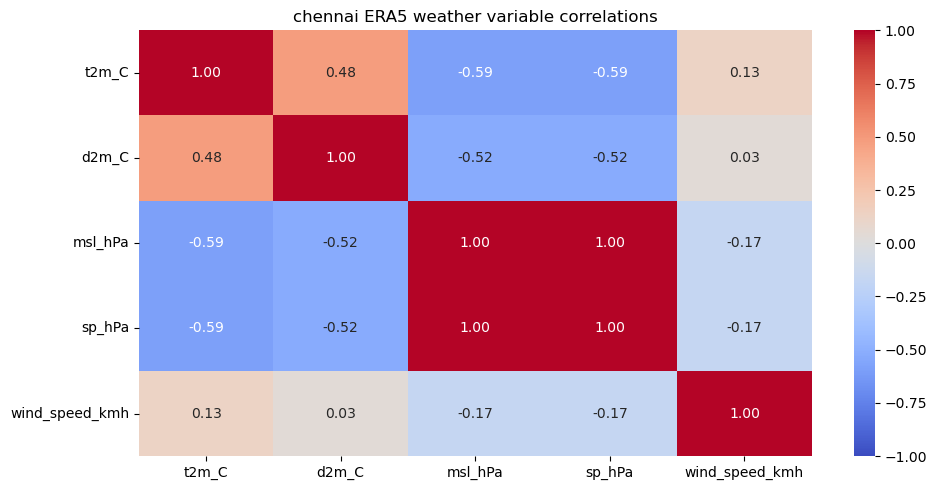

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
weather_vars = ["t2m_C","d2m_C","msl_hPa","sp_hPa","wind_speed_kmh"]
corr_matrix = weather[weather_vars].corr()
plt.figure(figsize=(10,5))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f",vmin=-1,vmax=1)
plt.title("chennai ERA5 weather variable correlations")
plt.tight_layout()
plt.show()

In [12]:
weather["valid_time"] = pd.to_datetime(weather["valid_time"])
weather = weather.sort_values("valid_time").reset_index(drop=True)
train = weather[weather["valid_time"] < "2025-01-01"].copy()
test = weather[weather["valid_time"] >= "2025-01-01"].copy()
print("training period:")
print(train["valid_time"].min(),"to",train["valid_time"].max())
print("\ntesting period:")
print(test["valid_time"].min(),"to",test["valid_time"].max())
print("training rows:",len(train))
print("testing rows:",len(test))

training period:
2020-01-01 00:00:00 to 2024-12-31 23:00:00

testing period:
2025-01-01 00:00:00 to 2025-12-31 23:00:00
training rows: 43848
testing rows: 8760


In [13]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual next-hour temperature values in the test period
y_test = test["t2m_C"].to_numpy()

# Persistence forecast: previous hour's actual temperature
all_temp = weather["t2m_C"].to_numpy()

test_start_idx = len(train)

y_pred_persistence = all_temp[
    test_start_idx - 1 : -1
]

# Evaluate
baseline_mae = mean_absolute_error(
    y_test, y_pred_persistence
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_persistence)
)

print("Persistence Walk-Forward Baseline")
print(f"MAE:  {baseline_mae:.3f} °C")
print(f"RMSE: {baseline_rmse:.3f} °C")
print("Actual test observations:", len(y_test))
print("Predictions:", len(y_pred_persistence))

Persistence Walk-Forward Baseline
MAE:  0.412 °C
RMSE: 0.598 °C
Actual test observations: 8760
Predictions: 8760


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create lagged features: only information from the previous hour
model_data = weather.copy()

feature_cols = [
    "t2m_C",
    "d2m_C",
    "msl_hPa",
    "wind_speed_kmh"
]

for col in feature_cols:
    model_data[f"{col}_lag1"] = model_data[col].shift(1)

# Target: temperature at the current hour
model_data["target_temp"] = model_data["t2m_C"]

lag_cols = [f"{col}_lag1" for col in feature_cols]

model_data = model_data.dropna(
    subset=lag_cols + ["target_temp"]
).reset_index(drop=True)

# Time-based split
train_lr = model_data[
    model_data["valid_time"] < "2025-01-01"
]

test_lr = model_data[
    model_data["valid_time"] >= "2025-01-01"
]

X_train = train_lr[lag_cols]
y_train = train_lr["target_temp"]

X_test = test_lr[lag_cols]
y_test_lr = test_lr["target_temp"]

# Train model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict
y_pred_lr = lr_model.predict(X_test)

# Evaluate
lr_mae = mean_absolute_error(y_test_lr, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test_lr, y_pred_lr))

print("Multivariate Linear Regression")
print(f"MAE:  {lr_mae:.3f} °C")
print(f"RMSE: {lr_rmse:.3f} °C")
print("Test observations:", len(y_test_lr))

Multivariate Linear Regression
MAE:  0.412 °C
RMSE: 0.591 °C
Test observations: 8760


In [15]:
import numpy as np
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Training and test temperature series
y_train_ar = train["t2m_C"].astype(float).to_numpy()
y_test_ar = np.asarray(y_test, dtype=float)

# Fit AR(3) using training data only
ar_model = AutoReg(y_train_ar, lags=3, trend="c").fit()

# Walk-forward, one-hour-ahead predictions
ar_history = list(y_train_ar)
ar_predictions = []

ar_params = ar_model.params

for actual in y_test_ar:
    previous_values = np.array(ar_history[-3:][::-1])

    prediction = ar_params[0] + np.dot(
        ar_params[1:], previous_values
    )

    ar_predictions.append(prediction)

    # Add the actual observed temperature for the next forecast
    ar_history.append(actual)

ar_predictions = np.array(ar_predictions)

ar_mae = mean_absolute_error(y_test_ar, ar_predictions)
ar_rmse = np.sqrt(mean_squared_error(y_test_ar, ar_predictions))

print("===== AR(3) WALK-FORWARD RESULTS =====")
print(f"MAE:  {ar_mae:.3f} °C")
print(f"RMSE: {ar_rmse:.3f} °C")
print("Test observations:", len(y_test_ar))

===== AR(3) WALK-FORWARD RESULTS =====
MAE:  0.367 °C
RMSE: 0.532 °C
Test observations: 8760


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Input features
feature_cols = [
    "t2m_C",
    "d2m_C",
    "msl_hPa",
    "wind_speed_kmh"
]

target_col = "t2m_C"
sequence_length = 24

# Preserve chronological order
train_lstm = train.copy()
test_lstm = test.copy()

# Check required columns
print("Training shape:", train_lstm.shape)
print("Testing shape:", test_lstm.shape)
print("Missing training values:")
print(train_lstm[feature_cols].isna().sum())
print("Missing testing values:")
print(test_lstm[feature_cols].isna().sum())

assert train_lstm[feature_cols + [target_col]].notna().all().all()
assert test_lstm[feature_cols + [target_col]].notna().all().all()

# Fit scalers using training data only
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

X_train_scaled = feature_scaler.fit_transform(
    train_lstm[feature_cols]
)
X_test_scaled = feature_scaler.transform(
    test_lstm[feature_cols]
)

y_train_scaled = target_scaler.fit_transform(
    train_lstm[[target_col]]
).ravel()

print("\nFeature scaling complete.")
print("Features:", feature_cols)
print("Sequence length:", sequence_length, "hours")

Training shape: (43848, 20)
Testing shape: (8760, 20)
Missing training values:
t2m_C             0
d2m_C             0
msl_hPa           0
wind_speed_kmh    0
dtype: int64
Missing testing values:
t2m_C             0
d2m_C             0
msl_hPa           0
wind_speed_kmh    0
dtype: int64

Feature scaling complete.
Features: ['t2m_C', 'd2m_C', 'msl_hPa', 'wind_speed_kmh']
Sequence length: 24 hours


In [17]:
# Training sequences
X_train_seq = []
y_train_seq = []

for i in range(sequence_length, len(X_train_scaled)):
    X_train_seq.append(
        X_train_scaled[i - sequence_length:i]
    )
    y_train_seq.append(
        y_train_scaled[i]
    )

X_train_seq = np.array(X_train_seq, dtype=np.float32)
y_train_seq = np.array(y_train_seq, dtype=np.float32)

# Test sequences: include the last 24 training hours as context
test_context = np.vstack([
    X_train_scaled[-sequence_length:],
    X_test_scaled
])

X_test_seq = []

for i in range(len(X_test_scaled)):
    X_test_seq.append(
        test_context[i:i + sequence_length]
    )

X_test_seq = np.array(X_test_seq, dtype=np.float32)

# Actual test temperatures, in original Celsius units
y_test_lstm = test_lstm[target_col].to_numpy(dtype=float)

print("X_train shape:", X_train_seq.shape)
print("y_train shape:", y_train_seq.shape)
print("X_test shape:", X_test_seq.shape)
print("y_test shape:", y_test_lstm.shape)

X_train shape: (43824, 24, 4)
y_train shape: (43824,)
X_test shape: (8760, 24, 4)
y_test shape: (8760,)


In [18]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

lstm_model = Sequential([
    tf.keras.Input(shape=(sequence_length, len(feature_cols))),
    LSTM(32, return_sequences=True),
    Dropout(0.2),
    LSTM(16),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 0.0079 - val_loss: 0.0130
Epoch 2/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 0.0039 - val_loss: 0.0061
Epoch 3/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 0.0027 - val_loss: 0.0034
Epoch 4/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.0021 - val_loss: 0.0018
Epoch 5/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 0.0016 - val_loss: 0.0012
Epoch 6/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 0.0013 - val_loss: 0.0010
Epoch 7/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 0.0012 - val_loss: 9.2095e-04
Epoch 8/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.0010 - val_loss: 8.0757e-04
Epoch 9/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 9.5009e-04 - val_loss: 7.4119e-04
Epoch 10/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 8.9142e-04 - val_loss: 7.1574e-04
Epoch 11/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - loss: 8.5140e-04 - val_loss: 6.3499e-04
Epoch 12

In [19]:
# Predict scaled temperature
y_pred_scaled = lstm_model.predict(
    X_test_seq,
    verbose=0
)

# Convert predictions back to Celsius
y_pred_lstm = target_scaler.inverse_transform(
    y_pred_scaled
).ravel()

lstm_mae = mean_absolute_error(
    y_test_lstm,
    y_pred_lstm
)

lstm_rmse = np.sqrt(
    mean_squared_error(y_test_lstm, y_pred_lstm)
)

print("===== MULTIVARIATE LSTM RESULTS =====")
print(f"MAE:  {lstm_mae:.3f} °C")
print(f"RMSE: {lstm_rmse:.3f} °C")
print("Test observations:", len(y_test_lstm))

===== MULTIVARIATE LSTM RESULTS =====
MAE:  0.350 °C
RMSE: 0.453 °C
Test observations: 8760


In [20]:
comparison = pd.DataFrame({
    "Model": [
        "Persistence",
        "Linear Regression",
        "AR(3)",
        "LSTM"
    ],
    "MAE (°C)": [
        baseline_mae,
        lr_mae,
        ar_mae,
        lstm_mae
    ],
    "RMSE (°C)": [
        baseline_rmse,
        lr_rmse,
        ar_rmse,
        lstm_rmse
    ]
})

display(comparison.round(3))

,Model,MAE (°C),RMSE (°C)
0,Persistence,0.412,0.598
1,Linear Regression,0.412,0.591
2,AR(3),0.367,0.532
3,LSTM,0.350,0.453


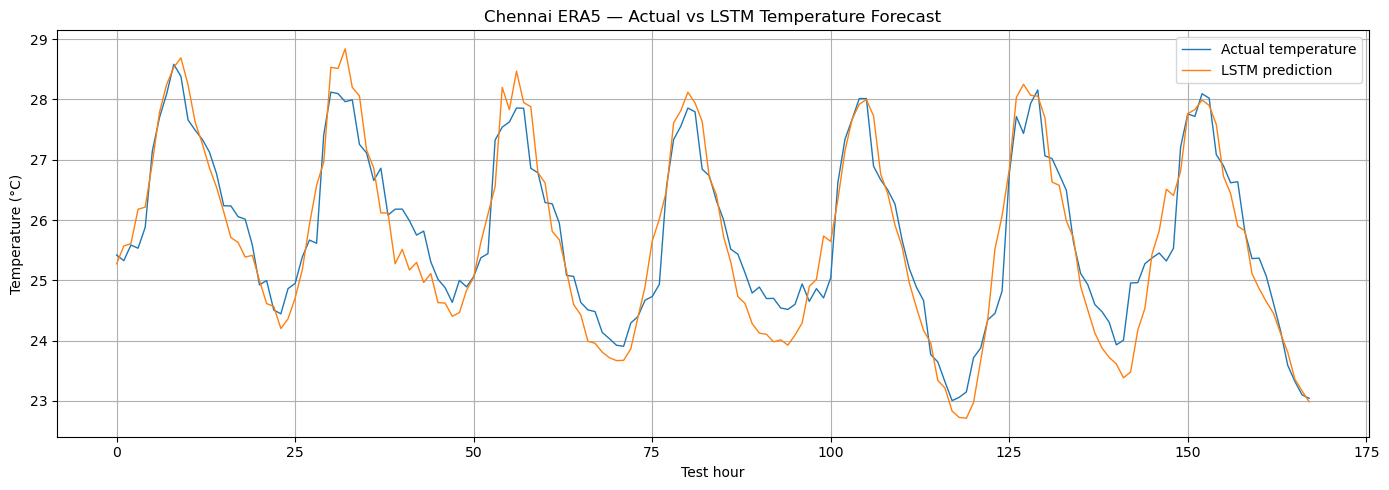

In [21]:
plot_hours = min(24 * 7, len(y_test_lstm))

plt.figure(figsize=(14, 5))

plt.plot(
    y_test_lstm[:plot_hours],
    label="Actual temperature",
    linewidth=1
)

plt.plot(
    y_pred_lstm[:plot_hours],
    label="LSTM prediction",
    linewidth=1
)

plt.title("Chennai ERA5 — Actual vs LSTM Temperature Forecast")
plt.xlabel("Test hour")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

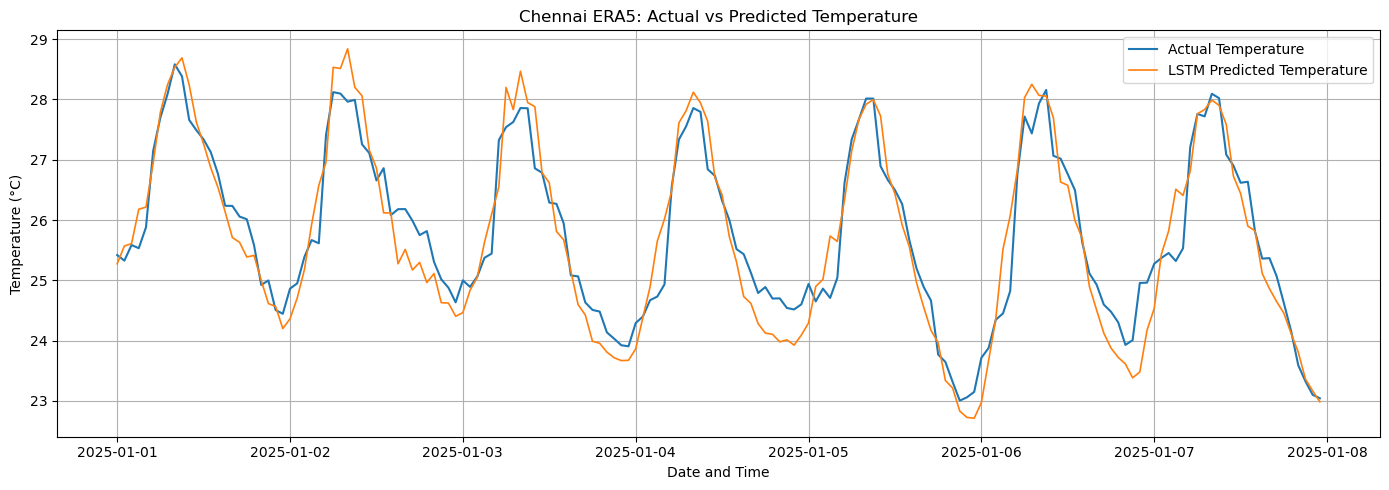

In [22]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# First 7 days of the test period
plot_hours = min(24 * 7, len(y_test_lstm))

plt.figure(figsize=(14, 5))

plt.plot(
    test_lstm["valid_time"].iloc[:plot_hours],
    y_test_lstm[:plot_hours],
    label="Actual Temperature",
    linewidth=1.5
)

plt.plot(
    test_lstm["valid_time"].iloc[:plot_hours],
    y_pred_lstm[:plot_hours],
    label="LSTM Predicted Temperature",
    linewidth=1.2
)

plt.title("Chennai ERA5: Actual vs Predicted Temperature")
plt.xlabel("Date and Time")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Mean residual: 0.0678 °C
Residual standard deviation: 0.4474 °C
Maximum absolute error: 3.2636 °C


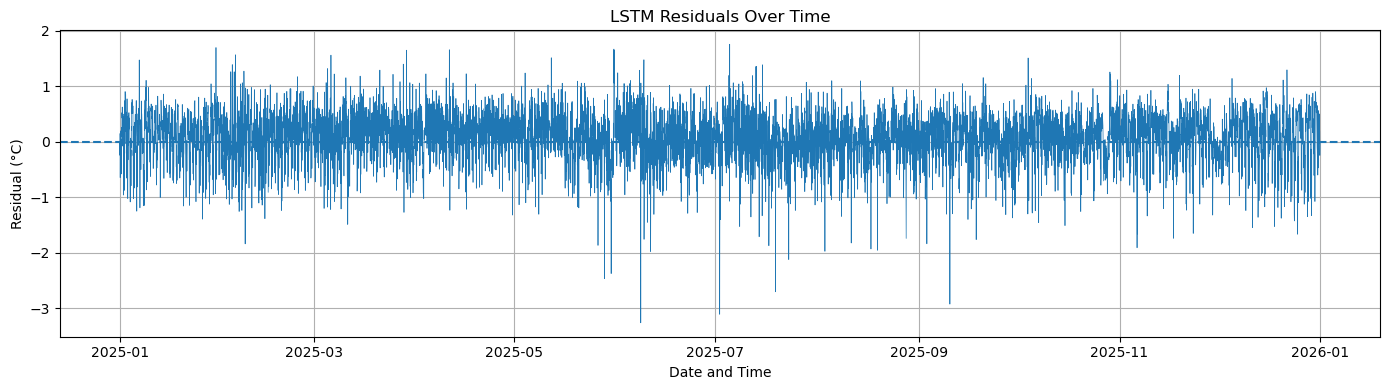

In [23]:
residuals = y_test_lstm - y_pred_lstm

print("Mean residual:", round(np.mean(residuals), 4), "°C")
print("Residual standard deviation:", round(np.std(residuals), 4), "°C")
print("Maximum absolute error:", round(np.max(np.abs(residuals)), 4), "°C")

plt.figure(figsize=(14, 4))

plt.plot(
    test_lstm["valid_time"],
    residuals,
    linewidth=0.5
)

plt.axhline(0, linestyle="--")
plt.title("LSTM Residuals Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Residual (°C)")
plt.grid(True)
plt.tight_layout()
plt.show()

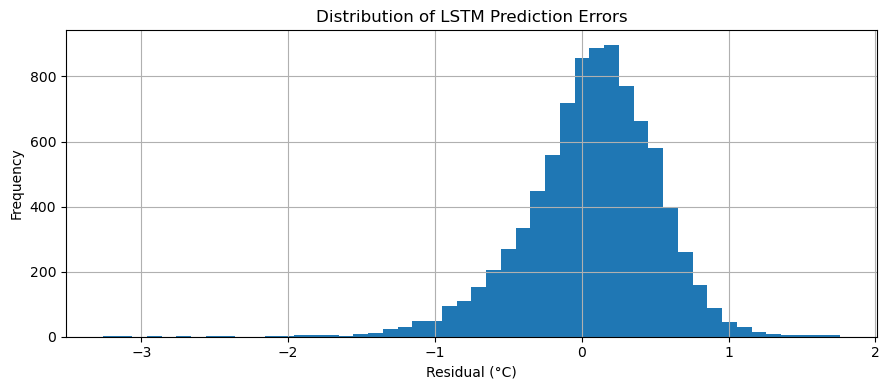

In [24]:
plt.figure(figsize=(9, 4))

plt.hist(residuals, bins=50)

plt.title("Distribution of LSTM Prediction Errors")
plt.xlabel("Residual (°C)")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

,Model,MAE,RMSE
0,Persistence,0.4117,0.5982
1,Linear Regression,0.4122,0.5910
2,AR(3),0.3674,0.5319
3,LSTM,0.3503,0.4525


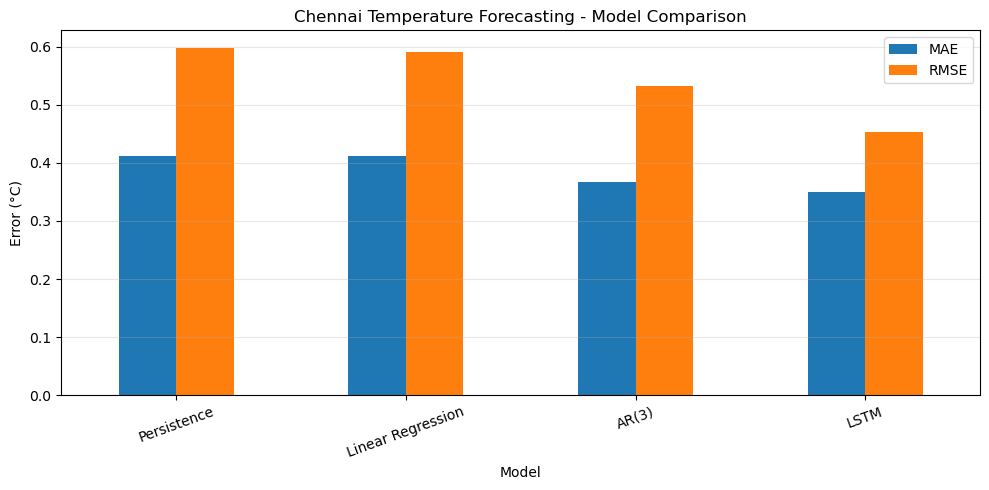

In [27]:
import matplotlib.pyplot as plt

model_results = pd.DataFrame({
    "Model": [
        "Persistence",
        "Linear Regression",
        "AR(3)",
        "LSTM"
    ],
    "MAE": [
        baseline_mae,
        lr_mae,
        ar_mae,
        lstm_mae
    ],
    "RMSE": [
        baseline_rmse,
        lr_rmse,
        ar_rmse,
        lstm_rmse
    ]
})

display(model_results.round(4))
model_results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Chennai Temperature Forecasting - Model Comparison")
plt.ylabel("Error (°C)")
plt.xlabel("Model")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

This project evaluates hourly temperature forecasting for Chennai using ERA5 reanalysis data from 2020 to 2025. Persistence, Linear Regression, AR(3), and LSTM models were evaluated using a chronological train-test split. Among the tested models, LSTM achieved the lowest reported test errors, with an MAE of approximately 0.350°C and RMSE of 0.453°C. These results suggest that LSTM performed best among the evaluated models for this one-hour-ahead forecasting task.